*Part of the [CNN & transfer learning](../README.md) project. Same 4,000/1,000 train/validation split
(seed 42) for every model; the 8,000-image test set is only used for the final evaluation of each model.*

# Deep Learning Assignment 2 — STL-10 Image Classification

### Setup, imports, GPU check and reproducibility

In [11]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA version used by PyTorch:", torch.version.cuda)
else:
    print("No GPU detected. Go to Runtime > Change runtime type > Hardware accelerator > GPU.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
CUDA available: True
GPU name: Tesla T4
CUDA version used by PyTorch: 12.8
Using device: cuda


In [12]:
# Imports and basic settings

import os
import random
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = "./data"
BATCH_SIZE = 64
NUM_WORKERS = 2

class_names = [
    "airplane", "bird", "car", "cat", "deer",
    "dog", "horse", "monkey", "ship", "truck"
]

print("Device:", device)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", len(class_names))
print("Classes:", class_names)

Device: cuda
Batch size: 64
Number of classes: 10
Classes: ['airplane', 'bird', 'car', 'cat', 'deer', 'dog', 'horse', 'monkey', 'ship', 'truck']


### Load STL-10 dataset

In [2]:
# Load STL-10 labeled train, labeled test, and unlabeled datasets

train_transform = transforms.Compose([
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
])

unlabeled_transform = transforms.Compose([
    transforms.ToTensor(),
])

train_full = datasets.STL10(
    root=DATA_DIR,
    split="train",
    download=True,
    transform=train_transform
)

test_dataset = datasets.STL10(
    root=DATA_DIR,
    split="test",
    download=True,
    transform=test_transform
)

unlabeled_dataset = datasets.STL10(
    root=DATA_DIR,
    split="unlabeled",
    download=True,
    transform=unlabeled_transform
)

print("Labeled train images:", len(train_full))
print("Test images:", len(test_dataset))
print("Unlabeled images:", len(unlabeled_dataset))

x, y = train_full[0]
print("One image tensor shape:", x.shape)
print("One label:", y, class_names[y])
print("Pixel value range:", float(x.min()), "to", float(x.max()))

100%|██████████| 2.64G/2.64G [08:59<00:00, 4.90MB/s]


Labeled train images: 5000
Test images: 8000
Unlabeled images: 100000
One image tensor shape: torch.Size([3, 96, 96])
One label: 1 bird
Pixel value range: 0.0 to 1.0


In [3]:
# Create train/validation split and DataLoaders

train_size = 4000
val_size = len(train_full) - train_size

train_dataset, val_dataset = random_split(
    train_full,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

unlabeled_loader = DataLoader(
    unlabeled_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Train split:", len(train_dataset))
print("Validation split:", len(val_dataset))
print("Test set:", len(test_dataset))
print("Unlabeled set:", len(unlabeled_dataset))

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Train split: 4000
Validation split: 1000
Test set: 8000
Unlabeled set: 100000
Batch image shape: torch.Size([64, 3, 96, 96])
Batch label shape: torch.Size([64])


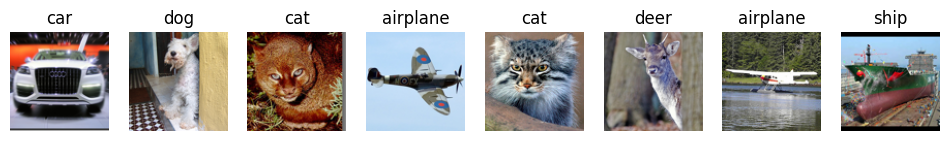

In [16]:
# Visualize a few STL-10 training images

def show_batch(images, labels, class_names, n=8):
    plt.figure(figsize=(12, 3))
    for i in range(n):
        img = images[i].permute(1, 2, 0).numpy()
        label = labels[i].item()

        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(class_names[label])
        plt.axis("off")

    plt.show()

images, labels = next(iter(train_loader))
show_batch(images, labels, class_names, n=8)

### Shared training and evaluation functions

In [13]:
# Shared training and evaluation functions

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    running_correct = 0
    running_total = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        _, preds = torch.max(outputs, 1)

        running_loss += loss.item() * images.size(0)
        running_correct += (preds == labels).sum().item()
        running_total += labels.size(0)

    epoch_loss = running_loss / running_total
    epoch_acc = running_correct / running_total

    return epoch_loss, epoch_acc


def evaluate(model, dataloader, criterion, device):
    model.eval()

    running_loss = 0.0
    running_correct = 0
    running_total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            _, preds = torch.max(outputs, 1)

            running_loss += loss.item() * images.size(0)
            running_correct += (preds == labels).sum().item()
            running_total += labels.size(0)

    epoch_loss = running_loss / running_total
    epoch_acc = running_correct / running_total

    return epoch_loss, epoch_acc


def fit_classifier(model, train_loader, val_loader, criterion, optimizer, device, epochs):
    history = []

    for epoch in range(epochs):
        start_time = time.time()

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        val_loss, val_acc = evaluate(
            model, val_loader, criterion, device
        )

        epoch_time = time.time() - start_time

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "time_sec": epoch_time
        })

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"train loss: {train_loss:.4f}, train acc: {train_acc:.4f} | "
            f"val loss: {val_loss:.4f}, val acc: {val_acc:.4f} | "
            f"time: {epoch_time:.1f}s"
        )

    return history


print("Training and evaluation functions are ready.")

Training and evaluation functions are ready.


### Custom CNN from scratch

In [17]:
# Custom CNN trained from scratch

class CustomCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            # Input: 3 x 96 x 96
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 x 48 x 48

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 64 x 24 x 24

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 128 x 12 x 12

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 256 x 6 x 6
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256 * 6 * 6, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


custom_cnn = CustomCNN(num_classes=10).to(device)

print(custom_cnn)

total_params = sum(p.numel() for p in custom_cnn.parameters())
trainable_params = sum(p.numel() for p in custom_cnn.parameters() if p.requires_grad)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

In [18]:
# Train Custom CNN

criterion = nn.CrossEntropyLoss()

custom_cnn_optimizer = optim.Adam(
    custom_cnn.parameters(),
    lr=0.001
)

CUSTOM_CNN_EPOCHS = 5

custom_cnn_history = fit_classifier(
    model=custom_cnn,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=custom_cnn_optimizer,
    device=device,
    epochs=CUSTOM_CNN_EPOCHS
)

Epoch 1/5 | train loss: 2.2542, train acc: 0.2430 | val loss: 1.7798, val acc: 0.3240 | time: 3.7s
Epoch 2/5 | train loss: 1.6423, train acc: 0.3583 | val loss: 1.5280, val acc: 0.3970 | time: 2.8s
Epoch 3/5 | train loss: 1.5102, train acc: 0.4120 | val loss: 1.5151, val acc: 0.4200 | time: 2.9s
Epoch 4/5 | train loss: 1.4097, train acc: 0.4497 | val loss: 1.7225, val acc: 0.3440 | time: 2.8s
Epoch 5/5 | train loss: 1.3252, train acc: 0.4875 | val loss: 1.3340, val acc: 0.4890 | time: 3.5s


In [19]:
# Evaluate Custom CNN on the STL-10 test set

custom_cnn_test_loss, custom_cnn_test_acc = evaluate(
    custom_cnn,
    test_loader,
    criterion,
    device
)

print(f"Custom CNN test loss: {custom_cnn_test_loss:.4f}")
print(f"Custom CNN test accuracy: {custom_cnn_test_acc:.4f}")

Custom CNN test loss: 1.3027
Custom CNN test accuracy: 0.5125


### ResNet18 transfer learning - frozen feature extractor


In [20]:
# DataLoaders for ImageNet-pretrained ResNet18

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

resnet_train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

resnet_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

train_full_resnet = datasets.STL10(
    root=DATA_DIR,
    split="train",
    download=False,
    transform=resnet_train_transform
)

test_dataset_resnet = datasets.STL10(
    root=DATA_DIR,
    split="test",
    download=False,
    transform=resnet_test_transform
)

# Use the same train/validation indices as before
train_dataset_resnet = torch.utils.data.Subset(train_full_resnet, train_dataset.indices)
val_dataset_resnet = torch.utils.data.Subset(train_full_resnet, val_dataset.indices)

train_loader_resnet = DataLoader(
    train_dataset_resnet,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader_resnet = DataLoader(
    val_dataset_resnet,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader_resnet = DataLoader(
    test_dataset_resnet,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

images, labels = next(iter(train_loader_resnet))

print("ResNet train split:", len(train_dataset_resnet))
print("ResNet validation split:", len(val_dataset_resnet))
print("ResNet test set:", len(test_dataset_resnet))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Batch min/max after normalization:", float(images.min()), float(images.max()))

ResNet train split: 4000
ResNet validation split: 1000
ResNet test set: 8000
Batch image shape: torch.Size([64, 3, 96, 96])
Batch label shape: torch.Size([64])
Batch min/max after normalization: -2.1179039478302 2.640000104904175


In [21]:
# ResNet18 transfer learning: frozen feature extractor

resnet18_frozen = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Freeze all pretrained layers
for param in resnet18_frozen.parameters():
    param.requires_grad = False

# Replace final classifier for STL-10: 10 classes
num_features = resnet18_frozen.fc.in_features
resnet18_frozen.fc = nn.Linear(num_features, 10)

resnet18_frozen = resnet18_frozen.to(device)

total_params = sum(p.numel() for p in resnet18_frozen.parameters())
trainable_params = sum(p.numel() for p in resnet18_frozen.parameters() if p.requires_grad)

print(resnet18_frozen)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 135MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [22]:
# Train ResNet18 frozen feature extractor

criterion = nn.CrossEntropyLoss()

resnet18_frozen_optimizer = optim.Adam(
    resnet18_frozen.fc.parameters(),
    lr=0.001
)

RESNET_FROZEN_EPOCHS = 5

resnet18_frozen_history = fit_classifier(
    model=resnet18_frozen,
    train_loader=train_loader_resnet,
    val_loader=val_loader_resnet,
    criterion=criterion,
    optimizer=resnet18_frozen_optimizer,
    device=device,
    epochs=RESNET_FROZEN_EPOCHS
)

Epoch 1/5 | train loss: 1.4282, train acc: 0.5300 | val loss: 0.9035, val acc: 0.7340 | time: 3.7s
Epoch 2/5 | train loss: 0.7932, train acc: 0.7655 | val loss: 0.7321, val acc: 0.7820 | time: 3.1s
Epoch 3/5 | train loss: 0.6835, train acc: 0.7900 | val loss: 0.6834, val acc: 0.7780 | time: 4.2s
Epoch 4/5 | train loss: 0.5980, train acc: 0.8107 | val loss: 0.6415, val acc: 0.7890 | time: 3.1s
Epoch 5/5 | train loss: 0.5614, train acc: 0.8193 | val loss: 0.6429, val acc: 0.7770 | time: 3.1s


In [23]:
# Evaluate ResNet18 frozen feature extractor on the STL-10 test set

resnet18_frozen_test_loss, resnet18_frozen_test_acc = evaluate(
    resnet18_frozen,
    test_loader_resnet,
    criterion,
    device
)

print(f"ResNet18 frozen test loss: {resnet18_frozen_test_loss:.4f}")
print(f"ResNet18 frozen test accuracy: {resnet18_frozen_test_acc:.4f}")

ResNet18 frozen test loss: 0.6591
ResNet18 frozen test accuracy: 0.7816


### ResNet18 transfer learning - partial fine-tuning

In [24]:
# ResNet18 transfer learning: partial fine-tuning
# Unfreeze layer4 + final classifier, keep earlier layers frozen

resnet18_finetune = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Freeze all layers first
for param in resnet18_finetune.parameters():
    param.requires_grad = False

# Replace final classifier for STL-10
num_features = resnet18_finetune.fc.in_features
resnet18_finetune.fc = nn.Linear(num_features, 10)

# Unfreeze layer4
for param in resnet18_finetune.layer4.parameters():
    param.requires_grad = True

# Make sure final classifier is trainable
for param in resnet18_finetune.fc.parameters():
    param.requires_grad = True

resnet18_finetune = resnet18_finetune.to(device)

total_params = sum(p.numel() for p in resnet18_finetune.parameters())
trainable_params = sum(p.numel() for p in resnet18_finetune.parameters() if p.requires_grad)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

print("\nTrainable parts:")
for name, param in resnet18_finetune.named_parameters():
    if param.requires_grad:
        print(name)

Total parameters: 11181642
Trainable parameters: 8398858

Trainable parts:
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


In [25]:
# Train ResNet18 partial fine-tuning

criterion = nn.CrossEntropyLoss()

resnet18_finetune_optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, resnet18_finetune.parameters()),
    lr=0.0001
)

RESNET_FINETUNE_EPOCHS = 5

resnet18_finetune_history = fit_classifier(
    model=resnet18_finetune,
    train_loader=train_loader_resnet,
    val_loader=val_loader_resnet,
    criterion=criterion,
    optimizer=resnet18_finetune_optimizer,
    device=device,
    epochs=RESNET_FINETUNE_EPOCHS
)

Epoch 1/5 | train loss: 0.9781, train acc: 0.6875 | val loss: 0.5077, val acc: 0.8300 | time: 4.5s
Epoch 2/5 | train loss: 0.2471, train acc: 0.9360 | val loss: 0.4543, val acc: 0.8420 | time: 3.8s
Epoch 3/5 | train loss: 0.0841, train acc: 0.9912 | val loss: 0.4314, val acc: 0.8490 | time: 3.4s
Epoch 4/5 | train loss: 0.0358, train acc: 0.9988 | val loss: 0.4343, val acc: 0.8550 | time: 3.3s
Epoch 5/5 | train loss: 0.0197, train acc: 0.9995 | val loss: 0.4358, val acc: 0.8550 | time: 4.4s


In [26]:
# Evaluate ResNet18 partial fine-tuning on the STL-10 test set

resnet18_finetune_test_loss, resnet18_finetune_test_acc = evaluate(
    resnet18_finetune,
    test_loader_resnet,
    criterion,
    device
)

print(f"ResNet18 partial fine-tuning test loss: {resnet18_finetune_test_loss:.4f}")
print(f"ResNet18 partial fine-tuning test accuracy: {resnet18_finetune_test_acc:.4f}")

ResNet18 partial fine-tuning test loss: 0.4100
ResNet18 partial fine-tuning test accuracy: 0.8634




### Convolutional autoencoder pretraining and encoder classifier

In [4]:
# Convolutional autoencoder for STL-10 unlabeled images

class ConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # Input: 3 x 96 x 96
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 x 48 x 48

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 64 x 24 x 24

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 128 x 12 x 12

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 256 x 6 x 6
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2),  # 128 x 12 x 12
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),   # 64 x 24 x 24
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),    # 32 x 48 x 48
            nn.ReLU(),

            nn.ConvTranspose2d(32, 3, kernel_size=2, stride=2),     # 3 x 96 x 96
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return reconstructed


autoencoder = ConvAutoencoder().to(device)

total_params = sum(p.numel() for p in autoencoder.parameters())
trainable_params = sum(p.numel() for p in autoencoder.parameters() if p.requires_grad)

print(autoencoder)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(2, 2), stride=(2, 2))
    (1): ReLU()
    (2): ConvTranspose2d(128, 64, kernel_size=(2, 2), stride=(2, 2))
    (3): ReLU()
    (4): ConvTranspose2d(64, 32, kernel_size=(2, 2), s

In [5]:
# Train convolutional autoencoder on unlabeled STL-10 images

def train_autoencoder_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    running_total = 0

    for images, _ in dataloader:
        images = images.to(device)

        optimizer.zero_grad()

        reconstructed = model(images)
        loss = criterion(reconstructed, images)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        running_total += images.size(0)

    epoch_loss = running_loss / running_total
    return epoch_loss


ae_criterion = nn.MSELoss()

ae_optimizer = optim.Adam(
    autoencoder.parameters(),
    lr=0.001
)

AE_EPOCHS = 2

autoencoder_history = []

for epoch in range(AE_EPOCHS):
    start_time = time.time()

    ae_loss = train_autoencoder_one_epoch(
        model=autoencoder,
        dataloader=unlabeled_loader,
        criterion=ae_criterion,
        optimizer=ae_optimizer,
        device=device
    )

    epoch_time = time.time() - start_time

    autoencoder_history.append({
        "epoch": epoch + 1,
        "ae_loss": ae_loss,
        "time_sec": epoch_time
    })

    print(
        f"Autoencoder epoch {epoch+1}/{AE_EPOCHS} | "
        f"reconstruction loss: {ae_loss:.6f} | "
        f"time: {epoch_time:.1f}s"
    )

Autoencoder epoch 1/2 | reconstruction loss: 0.015874 | time: 53.0s
Autoencoder epoch 2/2 | reconstruction loss: 0.009601 | time: 51.2s


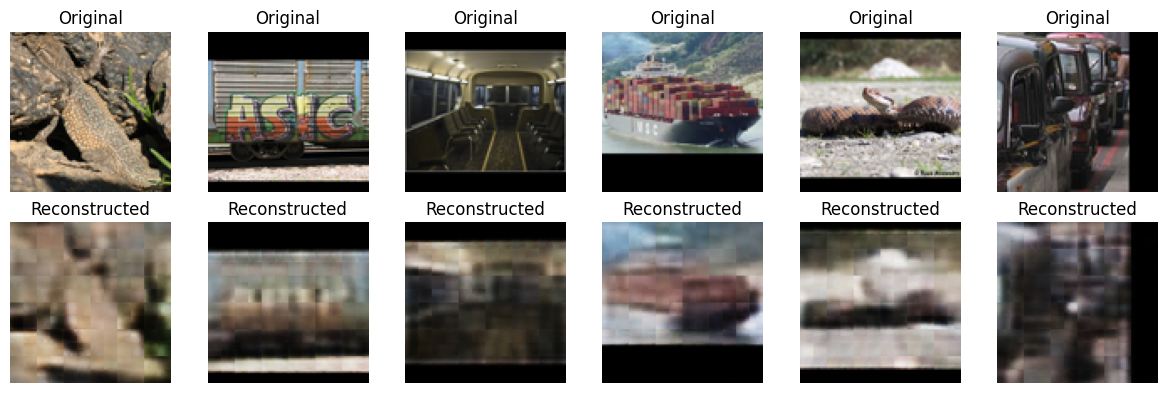

In [6]:
# Visualize original vs reconstructed images from the autoencoder

autoencoder.eval()

images, _ = next(iter(unlabeled_loader))
images = images.to(device)

with torch.no_grad():
    reconstructed = autoencoder(images)

images_cpu = images.cpu()
reconstructed_cpu = reconstructed.cpu()

n = 6
plt.figure(figsize=(12, 4))

for i in range(n):
    # Original image
    plt.subplot(2, n, i + 1)
    plt.imshow(images_cpu[i].permute(1, 2, 0).numpy())
    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_cpu[i].permute(1, 2, 0).numpy())
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Encoder classifier: use pretrained autoencoder encoder for STL-10 classification

class EncoderClassifier(nn.Module):
    def __init__(self, pretrained_encoder, num_classes=10, freeze_encoder=True):
        super().__init__()

        self.encoder = pretrained_encoder

        if freeze_encoder:
            for param in self.encoder.parameters():
                param.requires_grad = False

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256 * 6 * 6, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.classifier(x)
        return x


encoder_classifier = EncoderClassifier(
    pretrained_encoder=copy.deepcopy(autoencoder.encoder),
    num_classes=10,
    freeze_encoder=True
).to(device)

total_params = sum(p.numel() for p in encoder_classifier.parameters())
trainable_params = sum(p.numel() for p in encoder_classifier.parameters() if p.requires_grad)

print(encoder_classifier)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

EncoderClassifier(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.4, inplace=False)
    (2): Linear(in_features=9216, out_features=256, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.4, inplace=False)
    (5): Linear(in_fe

In [14]:
# Train autoencoder encoder classifier
# Encoder is frozen; only classifier head is trained

criterion = nn.CrossEntropyLoss()

encoder_classifier_optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, encoder_classifier.parameters()),
    lr=0.001
)

ENCODER_CLASSIFIER_EPOCHS = 5

encoder_classifier_history = fit_classifier(
    model=encoder_classifier,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=encoder_classifier_optimizer,
    device=device,
    epochs=ENCODER_CLASSIFIER_EPOCHS
)

Epoch 1/5 | train loss: 2.9665, train acc: 0.1635 | val loss: 1.9250, val acc: 0.2870 | time: 3.2s
Epoch 2/5 | train loss: 1.9697, train acc: 0.2328 | val loss: 1.7712, val acc: 0.2760 | time: 2.9s
Epoch 3/5 | train loss: 1.8915, train acc: 0.2333 | val loss: 1.6760, val acc: 0.3140 | time: 2.3s
Epoch 4/5 | train loss: 1.8298, train acc: 0.2620 | val loss: 1.6626, val acc: 0.3230 | time: 2.3s
Epoch 5/5 | train loss: 1.8078, train acc: 0.2560 | val loss: 1.6423, val acc: 0.3280 | time: 2.4s


In [15]:
# Evaluate autoencoder encoder classifier on the STL-10 test set

encoder_classifier_test_loss, encoder_classifier_test_acc = evaluate(
    encoder_classifier,
    test_loader,
    criterion,
    device
)

print(f"Autoencoder encoder classifier test loss: {encoder_classifier_test_loss:.4f}")
print(f"Autoencoder encoder classifier test accuracy: {encoder_classifier_test_acc:.4f}")

Autoencoder encoder classifier test loss: 1.6567
Autoencoder encoder classifier test accuracy: 0.3286


## Experiment comparison and conclusion

| Approach | Trainable params | Test accuracy |
|---|---:|---:|
| Custom CNN from scratch (5 epochs) | 2,751,498 | 0.5125 |
| ResNet-18, frozen backbone (linear probe) | 5,130 | 0.7816 |
| **ResNet-18, `layer4` + head fine-tuned** | 8,398,858 | **0.8634** |
| Conv autoencoder (2 epochs on 100k unlabeled) + frozen encoder + classifier | 2,362,122 | 0.3286 |

**Partial fine-tuning of ImageNet-pretrained ResNet-18 worked best.** Even the frozen backbone with only
a linear layer on top beats the CNN trained from scratch by about 27 points, which shows how much the
ImageNet features transfer with only 4,000 labelled images.

**Limits of these runs.** Every model was trained for 5 epochs without data augmentation, and the
fine-tuned ResNet reached 99.95% training accuracy against 85.5% validation accuracy, so it was
overfitting. The images were also fed to ResNet-18 at 96x96 although it was pretrained at 224x224.
`improvements/stl10_v2.py` addresses all three points.

**Autoencoder.** The encoder-based classifier did worse than the CNN trained from scratch. Two likely
reasons: the autoencoder trained for only 2 epochs, and a pixel-reconstruction objective rewards
keeping colour and texture detail rather than the class-level features needed here; with the encoder
frozen, the classifier cannot adapt them. Fine-tuning the encoder, or a contrastive pretraining
objective, would be the next things to try.
